torch 2.11.0+cu128 | gymnasium 1.3.0 | device: cpu
Rated wind speed of the physics model: 11.56 m/s
Misalignment weight lambda_gamma:      4.10
Baseline power at 15 m/s (aligned):  4.36 MW
Baseline power at 20 m/s (aligned):  10.34 MW


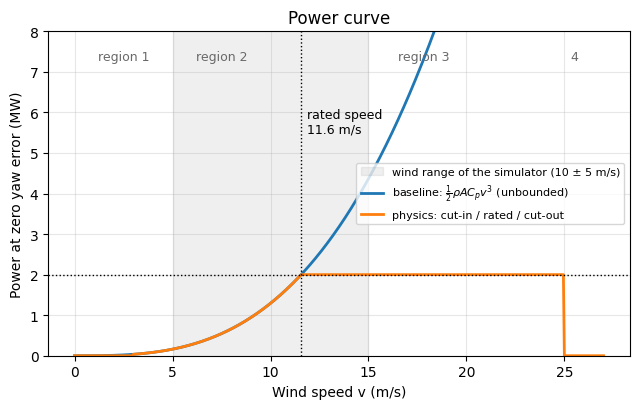

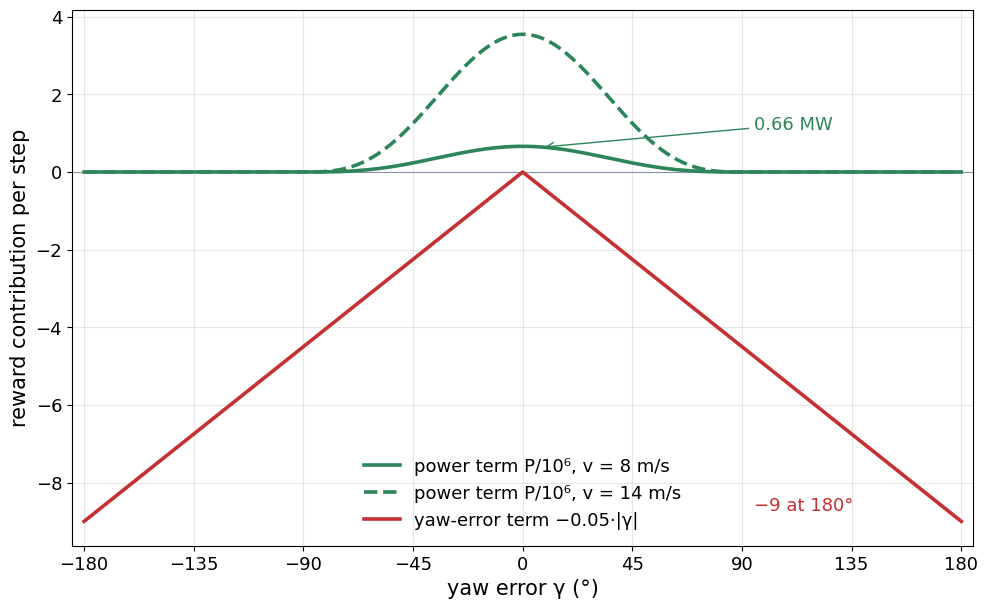

v = 8 m/s, gamma = 10 deg: real power loss 0.030 MW, degree penalty 0.50
PhysicsWindTurbineEnv consistent with the pure functions.
30 models found on disk, 0 to train with 15 processes


300 evaluation episodes of 3600 s in 72 s


,Baseline (original),Modified (physics-based),Change (%)
"Energy, physics eq. (MWh)",1.260 ± 0.005,1.230 ± 0.076,-2.43
"Energy, baseline eq. (MWh)",1.817 ± 0.005,1.770 ± 0.127,-2.54
Yaw efficiency (%),98.0 ± 0.4,95.7 ± 5.9,-2.43
Yaw efficiency after alignment (%),99.9 ± 0.1,97.3 ± 5.9,-2.57
Yaw-drive energy (kWh),8.920 ± 0.806,10.2 ± 1.0,14.18
Mean |γ| after alignment (°),2.835 ± 0.707,3.816 ± 4.942,34.60
RMS γ after alignment (°),3.617 ± 0.721,6.085 ± 9.013,68.23
Time within ±5° (%),83.3 ± 9.8,94.4 ± 7.3,13.31
Time within ±10° (%),98.4 ± 0.9,96.6 ± 7.7,-1.87
Alignment time (s),87.4 ± 7.8,83.9 ± 0.9,-4.00


,,share of time (%),mean |γ| (°),mean |ω| (°/s),mean power lost (kW)
region,controller,,,,
region 2 (v < rated),Baseline (original),56.617,2.820,0.451,2.911
region 3 (v ≥ rated),Baseline (original),43.383,2.854,0.411,0.069
region 2 (v < rated),Modified (physics-based),56.575,3.710,0.521,22.759
region 3 (v ≥ rated),Modified (physics-based),43.425,3.948,0.467,49.958
region 2 (v < rated),Baseline + circular obs.,56.572,1.359,0.559,0.755
region 3 (v ≥ rated),Baseline + circular obs.,43.428,1.500,0.472,0.010
region 2 (v < rated),Modified + circular obs.,56.573,1.405,0.480,0.684
region 3 (v ≥ rated),Modified + circular obs.,43.427,1.481,0.442,0.006


,Baseline (original),Modified (physics-based),Ablation: +P reward (absolute),Ablation: λγ = 1
"Energy, physics eq. (MWh)",1.260 ± 0.005,1.230 ± 0.076,1.242 ± 0.042,1.253 ± 0.021
Yaw efficiency after alignment (%),99.9 ± 0.1,97.3 ± 5.9,98.5 ± 2.8,99.2 ± 1.6
Mean |γ| after alignment (°),2.835 ± 0.707,3.816 ± 4.942,4.880 ± 2.677,3.561 ± 2.166
RMS γ after alignment (°),3.617 ± 0.721,6.085 ± 9.013,6.961 ± 4.944,5.054 ± 3.968
Time within ±5° (%),83.3 ± 9.8,94.4 ± 7.3,74.1 ± 7.4,83.9 ± 10.1
Alignment time (s),87.4 ± 7.8,83.9 ± 0.9,95.2 ± 12.7,87.1 ± 2.5
Yaw travel (°/h),1605.6 ± 145.1,1833.3 ± 175.1,1449.2 ± 50.5,1508.9 ± 106.9
Direction reversals (1/h),468.3 ± 154.8,651.4 ± 116.9,294.8 ± 65.9,373.3 ± 133.7


80 study models found on disk, 0 to train with 15 processes


800 evaluation episodes in 188 s


,models,failing_models,lost_episodes,energy_MWh,mean_abs_err
controller,,,,,
baseline,20,3,17.0,1.237,4.303
physics,20,7,41.0,1.232,4.257
baseline_circ,20,0,0.0,1.264,1.611
physics_circ,20,0,0.0,1.264,1.423


failing models with raw angles, baseline 3/20 vs physics 7/20: Fisher exact test p = 0.27
typical seed: 13 (rank 12, 12 of 20)


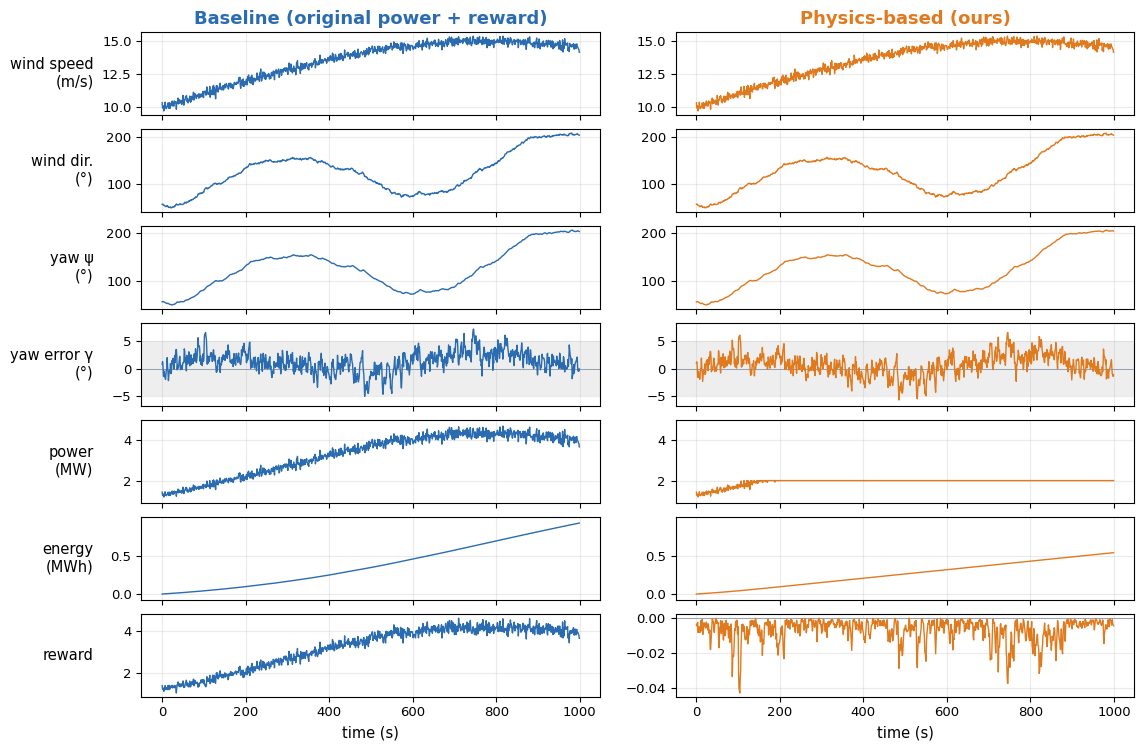

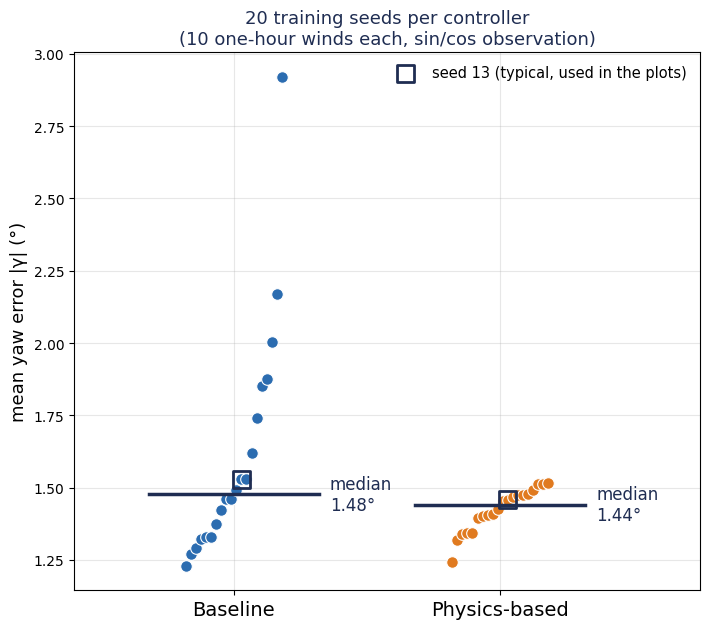

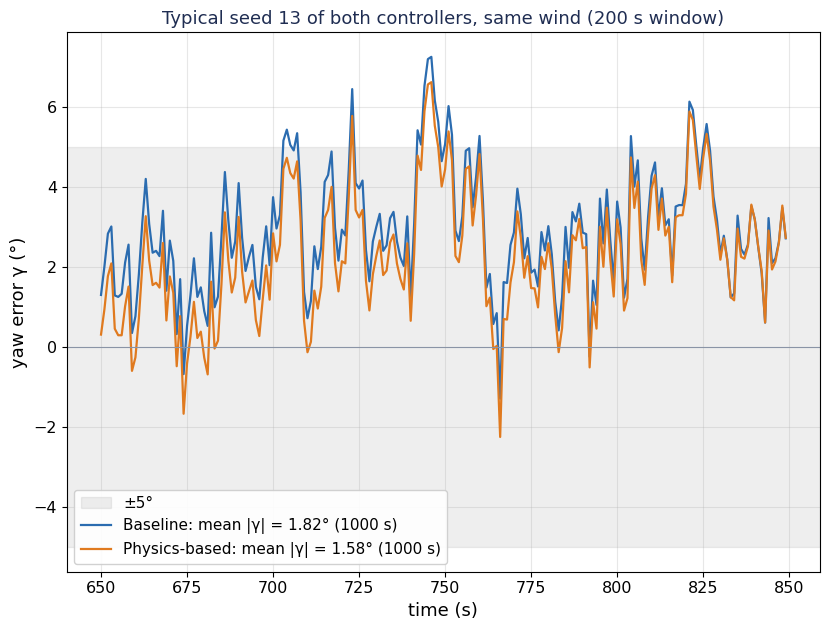

Baseline       seed 13, test wind: mean |γ| 1.82°, energy (own equation) 0.925 MWh, P max 4.72 MW
Physics-based  seed 13, test wind: mean |γ| 1.58°, energy (own equation) 0.539 MWh, P max 2.00 MW


,Baseline,Physics-based,p-value
sin/cos observation for both,,,
mean yaw error |γ| (°),1.61,1.42,0.0319
worst of the 20 seeds (°),2.92,1.52,NaN
time within ±5° (%),97.3,99.0,0.0007
yaw motion (°/h),1922,1734 (-9.8 %),0.0010
"energy, % of ideal",98.3,98.3,NaN
"failing models, raw → sin/cos",3/20 → 0/20,7/20 → 0/20,NaN


In [1]:
# Q1 — PPO yaw control of a wind turbine: physics-based power equation and reward
# Baseline: rl-wind.ipynb (PPO, Stable-Baselines3). Every section starts with a short explanation followed by its
# code. Tables are displayed and figures are shown (and saved in figures/) in the same order.
#
# Running: RETRAIN = False loads the models in models/ and logs/ (a few minutes); missing ones are trained
# (first run about 1.5 h on 16 threads). RETRAIN = True trains everything again (deterministic, same numbers).

# ====================================================================================================
# §1. Setup and configuration
# ====================================================================================================
# Problem
#   State (simulator): time t, wind speed v, wind direction theta_w, yaw psi. The yaw error
#       gamma = wrap(theta_w - psi) and the power P follow from them.
#   Observation: [v, theta_w, psi, gamma, P]; time and wind noise are hidden (partially observed).
#   Action: yaw rate omega in [-1, 1] deg/s, psi <- psi + omega * dt, dt = 1 s.
#   Wind: v = 10 + 5 sin(0.002 t) + N(0, 0.2^2); direction drifts with N(0, 1^2) deg per step. Continuing task.
#   Parameters: rho = 1.225 kg/m^3, R = 40 m, Cp = 0.42; PPO lr 3e-4, n_steps 2048, batch 64, 10 epochs,
#   gamma_RL = 0.99, GAE 0.95, clip 0.2, MLP 2x64, 300 000 steps (as in the original notebook).


import math
import os
import time
import multiprocessing as mp

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import gymnasium as gym
from gymnasium import spaces
from stable_baselines3 import PPO
from stable_baselines3.common.callbacks import BaseCallback
from IPython.display import display

torch.set_num_threads(1)          # a tiny MLP: one thread is the fastest option and keeps runs reproducible
DEVICE = "cpu"

RETRAIN = False                   # True -> train again even if saved models exist
SEEDS = [0, 1, 2, 3, 4]           # training seeds (one model per seed and per controller)
TOTAL_TIMESTEPS = 300_000         # same training budget as the original notebook

# PPO hyper-parameters: identical to the original notebook (all the others are SB3 defaults)
PPO_KWARGS = dict(
    policy="MlpPolicy",
    learning_rate=3e-4,
    n_steps=2048,
    batch_size=64,
    gamma=0.99,
)

TEST_SEED = 42                    # test wind of the final comparison (§9)
TEST_STEPS = 1000                 # same length as the original test (1000 s)
EVAL_SEEDS = list(range(100, 110))  # 10 one-hour winds for the evaluations of §7-§9
EVAL_STEPS = 3600                 # 1 hour each -> energy directly in MWh, covers below AND above rated wind

N_WORKERS = max(1, min(15, (os.cpu_count() or 2) - 1))   # parallel processes for training / evaluation

MODEL_DIR, LOG_DIR, FIG_DIR = "models", "logs", "figures"
for d in (MODEL_DIR, LOG_DIR, FIG_DIR):
    os.makedirs(d, exist_ok=True)

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
COLORS = {"baseline": "tab:blue", "physics": "tab:orange"}
LABELS = {"baseline": "Baseline (original)", "physics": "Modified (physics-based)"}

print("torch", torch.__version__, "| gymnasium", gym.__version__, "| device:", DEVICE)


# ====================================================================================================
# §2. Baseline environment (original code)
# ====================================================================================================
# The environment of rl-wind.ipynb, logic unchanged (only the comments were rewritten).


class WindTurbineEnv(gym.Env):
    # Wind turbine digital twin. The RL agent controls the yaw velocity. Time step dt = 1 s.

    def __init__(self):
        super().__init__()
        # Simulation parameters
        self.dt = 1.0                            # s

        # Turbine parameters
        self.rho = 1.225                         # air density [kg/m^3]
        self.radius = 40                         # rotor radius [m]
        self.area = np.pi * self.radius ** 2     # swept area [m^2]
        self.Cp = 0.42                           # power coefficient [-]

        # Yaw actuator
        self.max_yaw_speed = 1.0                 # deg/s

        # Observation: [wind speed, wind direction, yaw angle, yaw error, power]
        low = np.array([3, 0, 0, -180, 0], dtype=np.float32)
        high = np.array([20, 360, 360, 180, 10e6], dtype=np.float32)
        self.observation_space = spaces.Box(low, high, dtype=np.float32)

        # Action: yaw velocity command, -1 deg/s ... +1 deg/s
        self.action_space = spaces.Box(low=np.array([-1]), high=np.array([1]), dtype=np.float32)
        self.reset()

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.time = 0
        self.wind_speed = np.random.uniform(5, 12)
        self.wind_direction = np.random.uniform(0, 360)
        self.yaw = np.random.uniform(0, 360)
        self.power = 0
        return self.get_state(), {}

    def wind_model(self):
        # speed 3-20 m/s, direction 0-360 deg
        self.wind_speed = 10 + 5 * np.sin(0.002 * self.time) + np.random.normal(0, 0.2)
        self.wind_speed = np.clip(self.wind_speed, 3, 20)
        self.wind_direction += 0.5 * np.sin(0.01 * self.time) + np.random.normal(0, 1)
        self.wind_direction %= 360

    def turbine_power(self):
        yaw_error = (self.wind_direction - self.yaw)
        yaw_error = (yaw_error + 180) % 360 - 180          # wrap to [-180, 180)
        yaw_rad = np.deg2rad(yaw_error)
        # Power equation: P = 1/2 rho A Cp v^3 cos^3(gamma)
        power = 0.5 * self.rho * self.area * self.Cp * self.wind_speed ** 3 * np.cos(yaw_rad) ** 3
        return max(power, 0)

    def get_state(self):
        error = (self.wind_direction - self.yaw)
        error = (error + 180) % 360 - 180
        return np.array([self.wind_speed, self.wind_direction, self.yaw, error, self.power / 1e6],
                        dtype=np.float32)

    def step(self, action):
        self.time += self.dt

        # yaw actuator (ideal integrator)
        yaw_velocity = float(action[0])
        self.yaw += yaw_velocity * self.dt
        self.yaw %= 360

        # wind update
        self.wind_model()

        # power generation
        self.power = self.turbine_power()

        yaw_error = (self.wind_direction - self.yaw)
        yaw_error = (yaw_error + 180) % 360 - 180

        # reward: power [MW] - 0.05 * |yaw error| [deg] - 0.02 * |yaw rate| [deg/s]
        reward = self.power / 1e6 - 0.05 * abs(yaw_error) - 0.02 * abs(yaw_velocity)

        obs = self.get_state()
        terminated = False
        truncated = False
        return obs, reward, terminated, truncated, {}


# ====================================================================================================
# §3. Physics analysis of the baseline
# ====================================================================================================
# What is wrong in the baseline
#   P = 1/2 rho A Cp v^3 cos^3(gamma) has no generator limit (4.4 MW at 15 m/s) and cos^3 overestimates the
#   yaw loss. The reward r = P/1e6 - 0.05|gamma| - 0.02|omega| adds MW and degrees: at 8 m/s a 10 deg error
#   costs 0.5 while the real loss is 0.03 MW. Below: both power models as pure functions of (v, gamma).


# ---------------- shared physical constants (same values as the baseline) ----------------
RHO = 1.225                       # kg/m^3
RADIUS = 40.0                     # m
AREA = np.pi * RADIUS ** 2        # m^2
CP = 0.42                         # -
BETZ_LIMIT = 16 / 27              # maximum Cp of an ideal actuator disc
assert CP <= BETZ_LIMIT, "Cp must respect the Betz limit"

# ---------------- new parameters of the physics-based model (justified in §4) -------
RATED_POWER = 2.0e6               # W   generator rating of a 2 MW class, D = 80 m turbine
CUT_IN = 3.0                      # m/s below this speed the rotor does not produce power
CUT_OUT = 25.0                    # m/s above this speed the turbine is stopped (storm protection)
YAW_LOSS_EXPONENT = 1.88          # -   P ~ cos^p(gamma), p = 1.88 (Gebraad et al. 2016, NREL FLORIS)
YAW_DRIVE_POWER = 20e3            # W   yaw-system consumption at maximum yaw rate (~1 % of rated)
V_SITE_MAX = 15.0                 # m/s highest mean wind speed of the simulated site (10 + 5 m/s)

# rated wind speed: speed at which the ideal aerodynamic power reaches the generator rating
RATED_WIND_SPEED = (2 * RATED_POWER / (RHO * AREA * CP)) ** (1 / 3)


def wrap_deg(angle):
    # wrap an angle (deg) to [-180, 180)
    return (np.asarray(angle) + 180.0) % 360.0 - 180.0


def baseline_power(v, gamma_deg):
    # original model: P = 1/2 rho A Cp v^3 cos^3(gamma), negative values clipped to 0  [W]
    g = np.deg2rad(gamma_deg)
    return np.maximum(0.5 * RHO * AREA * CP * np.asarray(v) ** 3 * np.cos(g) ** 3, 0.0)


def aero_power(v, gamma_deg, p=YAW_LOSS_EXPONENT):
    # aerodynamic power captured with yaw misalignment: 1/2 rho A Cp v^3 max(cos gamma, 0)^p  [W]
    cos_g = np.maximum(np.cos(np.deg2rad(gamma_deg)), 0.0)
    return 0.5 * RHO * AREA * CP * np.asarray(v) ** 3 * cos_g ** p


def physics_power(v, gamma_deg):
    # electrical power with the operating regions of a pitch-regulated turbine  [W]
    #   region 1  : v < cut-in          -> 0
    #   region 2  : cut-in <= v < rated -> aerodynamic power (variable speed, Cp kept at its optimum)
    #   region 3  : rated <= v < cut-out-> limited to the rated power by blade pitch control
    #   region 4  : v >= cut-out        -> 0 (turbine shut down)
    v = np.asarray(v, dtype=float)
    p = np.minimum(aero_power(v, gamma_deg), RATED_POWER)
    return np.where((v >= CUT_IN) & (v < CUT_OUT), p, 0.0)


# weight of the inflow-misalignment term of the new reward (derivation in §4):
# same curvature at gamma = 0 as the aerodynamic power loss at the highest wind speed of the site
W_ALIGN = YAW_LOSS_EXPONENT * float(aero_power(V_SITE_MAX, 0.0)) / RATED_POWER

# sanity check: the pure function reproduces the original environment exactly
_env = WindTurbineEnv()
for _ in range(200):
    _env.wind_speed, _env.wind_direction, _env.yaw = np.random.uniform(3, 20), *np.random.uniform(0, 360, 2)
    assert np.isclose(_env.turbine_power(), baseline_power(_env.wind_speed,
                                                           wrap_deg(_env.wind_direction - _env.yaw)))
print(f"Rated wind speed of the physics model: {RATED_WIND_SPEED:.2f} m/s")
print(f"Misalignment weight lambda_gamma:      {W_ALIGN:.2f}")
print(f"Baseline power at 15 m/s (aligned):  {baseline_power(15, 0) / 1e6:.2f} MW")
print(f"Baseline power at 20 m/s (aligned):  {baseline_power(20, 0) / 1e6:.2f} MW")


# ====================================================================================================
# §3.1 Power curve
# ====================================================================================================
v = np.linspace(0, 27, 541)


def plot_power_curve(a):
    a.axvspan(5, 15, color="grey", alpha=0.12, label="wind range of the simulator (10 ± 5 m/s)")
    a.plot(v, baseline_power(v, 0) / 1e6, color=COLORS["baseline"], lw=2,
           label=r"baseline: $\frac{1}{2}\rho A C_p v^3$ (unbounded)")
    a.plot(v, physics_power(v, 0) / 1e6, color=COLORS["physics"], lw=2, label="physics: cut-in / rated / cut-out")
    a.axhline(RATED_POWER / 1e6, color="k", ls=":", lw=1)
    a.axvline(RATED_WIND_SPEED, color="k", ls=":", lw=1)
    a.text(RATED_WIND_SPEED + 0.3, 5.5, f"rated speed\n{RATED_WIND_SPEED:.1f} m/s", fontsize=9)
    for x, name in [(1.2, "region 1"), (6.2, "region 2"), (16.5, "region 3"), (25.3, "4")]:
        a.text(x, 7.3, name, fontsize=9, color="dimgrey")
    a.set(xlabel="Wind speed v (m/s)", ylabel="Power at zero yaw error (MW)", ylim=(0, 8), title="Power curve")
    a.legend(loc="center right", fontsize=8)


fig, ax = plt.subplots(figsize=(6.5, 4.2))
plot_power_curve(ax)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/power_curve.png", dpi=150)
plt.show()


# ====================================================================================================
# §3.2 Baseline reward terms
# ====================================================================================================
# The two terms of the baseline reward vs the yaw error (omega = 0): the degree penalty (down to -9 at 180 deg)
# dominates the power term, so the agent is judged on geometry, not on energy.


g = np.linspace(-180, 180, 721)
fig, ax = plt.subplots(figsize=(10, 6.2))
ax.axhline(0, color="#8A94A6", lw=0.8)
for vv, ls in ((8, "-"), (14, "--")):
    ax.plot(g, baseline_power(vv, g) / 1e6, color="#2F855A", ls=ls, lw=2.6, label=f"power term P/10⁶, v = {vv} m/s")
ax.plot(g, -0.05 * np.abs(g), color="#C53030", lw=2.6, label="yaw-error term −0.05·|γ|")
ax.annotate(f"{baseline_power(8, 0) / 1e6:.2f} MW", (8, 0.64), (95, 1.1), fontsize=13, color="#2F855A",
            arrowprops=dict(arrowstyle="->", color="#2F855A"))
ax.annotate("−9 at 180°", (175, -8.75), (95, -8.6), fontsize=13, color="#C53030", va="center")
ax.set_xlim(-185, 185)
ax.set_xticks(range(-180, 181, 45))
ax.set_xlabel("yaw error γ (°)", fontsize=15)
ax.set_ylabel("reward contribution per step", fontsize=15)
ax.tick_params(labelsize=13)
ax.grid(alpha=0.3)
ax.legend(loc="lower center", fontsize=13, frameon=False)
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/baseline_reward_terms.png", dpi=150, facecolor="white")
plt.show()
print(f"v = 8 m/s, gamma = 10 deg: real power loss {(baseline_power(8, 0) - baseline_power(8, 10)) / 1e6:.3f} MW, "
      f"degree penalty {0.05 * 10:.2f}")


# ====================================================================================================
# §4. Modified environment — physics-based power equation and reward
# ====================================================================================================
# Our modifications
#   Power:  P_e = min(P_rated, 1/2 rho A Cp v^3 cos^1.88(gamma)) for 3 <= v < 25 m/s, P_rated = 2 MW
#           (cos^1.88: yaw loss fitted on high-fidelity simulations, Gebraad et al. 2016 / NREL FLORIS).
#   Reward: r = -[ (P_e(v,0) - P_e(v,gamma)) / P_rated            energy lost by misalignment
#                  + (P_yaw,max / P_rated) |omega| / omega_max     yaw-motor energy, P_yaw,max = 20 kW
#                  + lambda_gamma (1 - cos gamma) ]                 smooth misalignment term
#   lambda_gamma = 1.88 * P_aero(15 m/s) / P_rated ~ 4.1 (same curvature as the aerodynamic loss at 15 m/s).
#   The "energy lost" form has the same optimal policy as +P (the wind does not depend on the actions) but much
#   less variance. r <= 0, maximum 0 when aligned and still.


class PhysicsWindTurbineEnv(WindTurbineEnv):
    # Same wind, observation, action and actuator as the baseline.
    # Only the power equation (turbine_power) and the reward (step) are replaced.

    def __init__(self, rated_power=RATED_POWER, cut_in=CUT_IN, cut_out=CUT_OUT,
                 yaw_loss_exponent=YAW_LOSS_EXPONENT, yaw_drive_power=YAW_DRIVE_POWER,
                 w_align=W_ALIGN, reward_form="loss"):
        assert reward_form in ("loss", "absolute")
        self.rated_power = rated_power
        self.cut_in = cut_in
        self.cut_out = cut_out
        self.yaw_loss_exponent = yaw_loss_exponent
        self.yaw_drive_power = yaw_drive_power
        self.w_align = w_align
        self.reward_form = reward_form      # "loss" (main) or "absolute" (+P_e, ablation of §7.2)
        super().__init__()
        assert self.Cp <= 16 / 27, "Cp above the Betz limit"
        self.rated_wind_speed = (2 * rated_power / (self.rho * self.area * self.Cp)) ** (1 / 3)

    def yaw_error(self):
        return float(wrap_deg(self.wind_direction - self.yaw))

    def electrical_power(self, v, gamma_deg):
        # electrical power [W]: cut-in, cos^p yaw loss, rated power (pitch control), cut-out
        if v < self.cut_in or v >= self.cut_out:
            return 0.0
        cos_g = max(np.cos(np.deg2rad(gamma_deg)), 0.0)
        p_aero = 0.5 * self.rho * self.area * self.Cp * v ** 3 * cos_g ** self.yaw_loss_exponent
        return min(p_aero, self.rated_power)

    def turbine_power(self):
        return self.electrical_power(self.wind_speed, self.yaw_error())

    def reward_terms(self, yaw_velocity):
        # the three reward terms, in per-unit of the rated power (all >= 0, they are subtracted)
        if self.reward_form == "loss":
            energy = (self.electrical_power(self.wind_speed, 0.0) - self.power) / self.rated_power
        else:                                   # "absolute": -energy = produced energy (same optimum)
            energy = -self.power / self.rated_power
        yaw_drive = self.yaw_drive_power * abs(yaw_velocity) / self.max_yaw_speed / self.rated_power
        misalignment = self.w_align * (1.0 - np.cos(np.deg2rad(self.yaw_error())))
        return energy, yaw_drive, misalignment

    def step(self, action):
        self.time += self.dt

        # yaw actuator (unchanged; SB3 already clips the action, the clip here only protects manual calls)
        yaw_velocity = float(np.clip(action[0], -self.max_yaw_speed, self.max_yaw_speed))
        self.yaw = (self.yaw + yaw_velocity * self.dt) % 360

        # wind update (unchanged)
        self.wind_model()

        # power generation (new equation)
        self.power = self.turbine_power()

        # reward (new, per-unit)
        energy, yaw_drive, misalignment = self.reward_terms(yaw_velocity)
        reward = -(energy + yaw_drive + misalignment)

        info = {"r_energy": -energy, "r_yaw_drive": -yaw_drive, "r_misalignment": -misalignment}
        return self.get_state(), float(reward), False, False, info


def physics_reward(v, gamma_deg, omega, w_align=W_ALIGN):
    # pure-function version of the new reward ("loss" form), used for plots
    lost = (physics_power(v, 0.0) - physics_power(v, gamma_deg)) / RATED_POWER
    yaw_drive = YAW_DRIVE_POWER * np.abs(omega) / RATED_POWER
    return -(lost + yaw_drive + w_align * (1 - np.cos(np.deg2rad(gamma_deg))))


# check: the environment and the pure functions give the same numbers
_env = PhysicsWindTurbineEnv()
for _ in range(200):
    _env.wind_speed, _env.wind_direction, _env.yaw = np.random.uniform(3, 20), *np.random.uniform(0, 360, 2)
    _env.power = _env.turbine_power()
    _g = wrap_deg(_env.wind_direction - _env.yaw)
    assert np.isclose(_env.power, physics_power(_env.wind_speed, _g))
    assert np.isclose(-sum(_env.reward_terms(0.3)), physics_reward(_env.wind_speed, _g, 0.3))
print("PhysicsWindTurbineEnv consistent with the pure functions.")


# ====================================================================================================
# §5. Training
# ====================================================================================================
# Training: six variants x five seeds, same PPO settings and budget. Variants: baseline, physics (ours),
# two ablations (+P form, lambda_gamma = 1) and baseline/physics with the (sin, cos) angle encoding of §8.


class CircularObservation(gym.ObservationWrapper):
    # Replaces the raw angles theta_w and psi (discontinuous at 0/360 deg) with (sin, cos) pairs:
    #   [v, theta_w, psi, gamma, P]  ->  [v, sin theta_w, cos theta_w, sin psi, cos psi, gamma, P]
    # The wrapped environment (dynamics, power, reward) is not modified.

    def __init__(self, env):
        super().__init__(env)
        low = np.array([3, -1, -1, -1, -1, -180, 0], dtype=np.float32)
        high = np.array([20, 1, 1, 1, 1, 180, 10e6], dtype=np.float32)
        self.observation_space = spaces.Box(low, high, dtype=np.float32)

    @staticmethod
    def to_circular(obs):
        th, psi = np.deg2rad(obs[1]), np.deg2rad(obs[2])
        return np.array([obs[0], np.sin(th), np.cos(th), np.sin(psi), np.cos(psi), obs[3], obs[4]],
                        dtype=np.float32)

    def observation(self, obs):
        return self.to_circular(obs)


# name: (environment class, constructor kwargs, circular observation?)
VARIANTS = {
    "baseline":         (WindTurbineEnv, {}, False),
    "physics":          (PhysicsWindTurbineEnv, {}, False),
    "physics_absolute": (PhysicsWindTurbineEnv, {"reward_form": "absolute"}, False),
    "physics_lambda1":  (PhysicsWindTurbineEnv, {"w_align": 1.0}, False),
    "baseline_circ":    (WindTurbineEnv, {}, True),
    "physics_circ":     (PhysicsWindTurbineEnv, {}, True),
}
MAIN_VARIANTS = ["baseline", "physics", "physics_absolute", "physics_lambda1"]
COLORS.update({"physics_absolute": "tab:green", "physics_lambda1": "tab:purple",
               "baseline_circ": "tab:cyan", "physics_circ": "tab:red"})
LABELS.update({"physics_absolute": "Ablation: +P reward (absolute)",
               "physics_lambda1": "Ablation: λγ = 1",
               "baseline_circ": "Baseline + circular obs.",
               "physics_circ": "Modified + circular obs."})


def make_env(name):
    cls, kwargs, circular = VARIANTS[name]
    env = cls(**kwargs)
    return CircularObservation(env) if circular else env


class TrainingLogger(BaseCallback):
    # Stores, for every rollout, the mean step reward and the mean |yaw error| seen during training.

    def __init__(self):
        super().__init__()
        self._rewards, self._abs_err = [], []
        self.timesteps, self.mean_reward, self.mean_abs_err = [], [], []

    def _on_step(self):
        turbine = self.training_env.envs[0].unwrapped          # physical state, independent of the observation
        self._rewards.append(float(self.locals["rewards"][0]))
        self._abs_err.append(abs(float(wrap_deg(turbine.wind_direction - turbine.yaw))))
        return True

    def _on_rollout_end(self):
        self.timesteps.append(self.num_timesteps)
        self.mean_reward.append(np.mean(self._rewards))
        self.mean_abs_err.append(np.mean(self._abs_err))
        self._rewards, self._abs_err = [], []


def model_path(name, seed):
    return f"{MODEL_DIR}/ppo_yaw_{name}_seed{seed}"


def log_path(name, seed):
    return f"{LOG_DIR}/train_{name}_seed{seed}.npz"


def train_job(job):
    # trains one (variant, seed) pair in its own process and saves model + training log
    name, seed = job
    torch.set_num_threads(1)
    np.random.seed(seed)                                  # the wind uses the global numpy generator
    model = PPO(env=make_env(name), seed=seed, device=DEVICE, verbose=0, **PPO_KWARGS)
    logger = TrainingLogger()
    t0 = time.time()
    model.learn(total_timesteps=TOTAL_TIMESTEPS, callback=logger)
    model.save(model_path(name, seed))
    np.savez(log_path(name, seed), timesteps=np.array(logger.timesteps),
             mean_reward=np.array(logger.mean_reward), mean_abs_err=np.array(logger.mean_abs_err))
    return name, seed, time.time() - t0


jobs = [(name, seed) for name in VARIANTS for seed in SEEDS]
todo = [j for j in jobs if RETRAIN or not (os.path.exists(model_path(*j) + ".zip") and os.path.exists(log_path(*j)))]
print(f"{len(jobs) - len(todo)} models found on disk, {len(todo)} to train with {N_WORKERS} processes")
if todo:
    t0 = time.time()
    with mp.get_context("fork").Pool(min(N_WORKERS, len(todo))) as pool:
        for name, seed, dt_train in pool.imap_unordered(train_job, todo):
            print(f"  trained {name:17s} seed {seed} in {dt_train:5.0f} s")
    print(f"total training wall time: {(time.time() - t0) / 60:.1f} min")

models = {j: PPO.load(model_path(*j), device=DEVICE) for j in jobs}


# ====================================================================================================
# §6. Evaluation loop (test loop of the original notebook)
# ====================================================================================================
# Test loop of the original notebook (7 signals); np.random.seed(wind_seed) gives every controller the same wind.


def run_episode(model, name, n_steps, wind_seed, deterministic=True):
    np.random.seed(wind_seed)
    env = make_env(name)
    turbine = env.unwrapped              # physical state (identical for wrapped and unwrapped variants)
    obs, _ = env.reset()
    dt = turbine.dt
    keys = ["speed", "direction", "yaw", "error", "power", "energy", "reward", "action",
            "p_baseline_eq", "p_physics_eq", "p_physics_ideal"]
    ep = {k: [] for k in keys}
    total_energy = 0.0
    for t in range(n_steps):
        action, _ = model.predict(obs, deterministic=deterministic)
        obs, reward, done, trunc, _ = env.step(action)
        # same quantities as obs[0..4] of the original test loop, read from the simulator state so that
        # the loop also works with the circular observation of §8
        gamma = float(wrap_deg(turbine.wind_direction - turbine.yaw))
        power_mw = turbine.power / 1e6                      # MW, power of the environment's own model
        ep["speed"].append(turbine.wind_speed)
        ep["direction"].append(turbine.wind_direction)
        ep["yaw"].append(turbine.yaw)
        ep["error"].append(gamma)
        ep["power"].append(power_mw)
        total_energy += power_mw * dt / 3600                # MWh
        ep["energy"].append(total_energy)
        ep["reward"].append(reward)
        ep["action"].append(float(np.clip(action[0], -1, 1)))
        ep["p_baseline_eq"].append(baseline_power(turbine.wind_speed, gamma) / 1e6)
        ep["p_physics_eq"].append(physics_power(turbine.wind_speed, gamma) / 1e6)
        ep["p_physics_ideal"].append(physics_power(turbine.wind_speed, 0.0) / 1e6)   # perfect alignment
    return {k: np.asarray(v, dtype=float) for k, v in ep.items()}


# ====================================================================================================
# §7. Quantitative comparison (5 training seeds × 10 winds × 1 hour, raw angles)
# ====================================================================================================
# Quantitative comparison: every model on the same 10 one-hour winds; mean +- std over the seeds.


def episode_metrics(ep):
    abs_err = np.abs(ep["error"])
    aligned = np.flatnonzero(abs_err < 5.0)
    t_align = int(aligned[0]) if len(aligned) else len(abs_err)
    after = slice(t_align, None)
    a = ep["action"]
    moving = a[np.abs(a) > 0.05]                                    # ignore tiny commands for reversals
    hours = len(abs_err) / 3600
    e_phys = ep["p_physics_eq"].sum() / 3600
    return {
        "Energy, physics eq. (MWh)": e_phys,
        "Energy, baseline eq. (MWh)": ep["p_baseline_eq"].sum() / 3600,
        "Yaw efficiency (%)": 100 * e_phys / (ep["p_physics_ideal"].sum() / 3600),
        "Yaw efficiency after alignment (%)": 100 * ep["p_physics_eq"][after].sum() / ep["p_physics_ideal"][after].sum(),
        "Yaw-drive energy (kWh)": YAW_DRIVE_POWER * np.abs(a).sum() / 3.6e6,
        "Mean |γ| after alignment (°)": abs_err[after].mean(),
        "RMS γ after alignment (°)": np.sqrt(np.mean(abs_err[after] ** 2)),
        "Time within ±5° (%)": 100 * np.mean(abs_err[after] < 5),
        "Time within ±10° (%)": 100 * np.mean(abs_err[after] < 10),
        "Alignment time (s)": t_align,
        "Yaw travel (°/h)": np.abs(a).sum() / hours,
        "Direction reversals (1/h)": np.sum(np.diff(np.sign(moving)) != 0) / hours,
    }


def eval_job(job):
    # evaluates one trained model on all the evaluation winds (runs in its own process)
    name, seed = job
    torch.set_num_threads(1)
    model = PPO.load(model_path(name, seed), device=DEVICE)
    return name, seed, [run_episode(model, name, EVAL_STEPS, ws) for ws in EVAL_SEEDS]


t0 = time.time()
eval_eps = {}
with mp.get_context("fork").Pool(min(N_WORKERS, len(jobs))) as pool:
    for name, seed, eps in pool.imap_unordered(eval_job, jobs):
        for ws, ep in zip(EVAL_SEEDS, eps):
            eval_eps[name, seed, ws] = ep
print(f"{len(eval_eps)} evaluation episodes of {EVAL_STEPS} s in {time.time() - t0:.0f} s")

# the wind is the same for every controller (same wind seed)
for name, seed in jobs:
    assert np.allclose(eval_eps[name, seed, EVAL_SEEDS[0]]["speed"], eval_eps["baseline", SEEDS[0], EVAL_SEEDS[0]]["speed"])

results = pd.DataFrame([{"controller": n, "train_seed": s, "wind_seed": w, **episode_metrics(ep)}
                        for (n, s, w), ep in eval_eps.items()])
results.to_csv(f"{LOG_DIR}/evaluation_results.csv", index=False)

# mean over the wind realisations for every trained model, then mean ± std over the training seeds
per_model = results.groupby(["controller", "train_seed"]).mean(numeric_only=True).drop(columns="wind_seed")
summary_mean = per_model.groupby("controller").mean().T
summary_std = per_model.groupby("controller").std().T


def fmt(m, s):
    return f"{m:.3f} ± {s:.3f}" if abs(m) < 10 else f"{m:.1f} ± {s:.1f}"


def comparison_table(names):
    tab = pd.DataFrame({LABELS[n]: [fmt(m, s) for m, s in zip(summary_mean[n], summary_std[n])] for n in names},
                       index=summary_mean.index)
    if len(names) == 2:
        a, c = names
        tab["Change (%)"] = (100 * (summary_mean[c] - summary_mean[a]) / summary_mean[a]).round(2)
    return tab


display(comparison_table(["baseline", "physics"]))


# ====================================================================================================
# §7.1 Below vs above rated wind
# ====================================================================================================
# Tracking error and yaw activity below vs above the rated wind speed (11.6 m/s).


region_rows = []
for (name, seed, ws), ep in eval_eps.items():
    if name not in ("baseline", "physics", "baseline_circ", "physics_circ"):
        continue
    abs_err = np.abs(ep["error"])
    t_align = int(np.argmax(abs_err < 5))
    v_, e_, a_ = ep["speed"][t_align:], abs_err[t_align:], np.abs(ep["action"][t_align:])
    lost = (ep["p_physics_ideal"] - ep["p_physics_eq"])[t_align:]
    for region, mask in (("region 2 (v < rated)", v_ < RATED_WIND_SPEED),
                         ("region 3 (v ≥ rated)", v_ >= RATED_WIND_SPEED)):
        region_rows.append({"region": region, "controller": LABELS[name],
                            "share of time (%)": 100 * mask.mean(),
                            "mean |γ| (°)": e_[mask].mean(), "mean |ω| (°/s)": a_[mask].mean(),
                            "mean power lost (kW)": 1000 * lost[mask].mean()})
region_df = pd.DataFrame(region_rows).groupby(["region", "controller"], sort=False).mean(numeric_only=True)
display(region_df.round(3))


# ====================================================================================================
# §7.2 Ablation of the reward design
# ====================================================================================================
# Ablation of the reward: +P instead of the energy-lost form, and lambda_gamma = 1.


ablation_metrics = ["Energy, physics eq. (MWh)", "Yaw efficiency after alignment (%)",
                    "Mean |γ| after alignment (°)", "RMS γ after alignment (°)", "Time within ±5° (%)",
                    "Alignment time (s)", "Yaw travel (°/h)", "Direction reversals (1/h)"]
display(comparison_table(MAIN_VARIANTS).loc[ablation_metrics])


# ====================================================================================================
# §8. Seed study (20 seeds): the 0/360° flaw and its fix
# ====================================================================================================
# The 0/360 deg flaw: the raw angles theta_w, psi jump by 360 deg when the wind crosses north, a state rare in
# training, so some models turn the wrong way for minutes. Fix: encode each angle as (sin, cos).
# 20 seeds of baseline / physics, with raw and with sin/cos angles, each on the same 10 one-hour winds. A model
# "fails" if it loses the wind (> 5 % of an episode at |gamma| > 30 deg after the initial alignment).


STUDY_SEEDS = list(range(20))                      # 0-4: models of the main study, 5-19: new
STUDY_VARIANTS = ["baseline", "physics", "baseline_circ", "physics_circ"]
study_jobs = [(n, s) for n in STUDY_VARIANTS for s in STUDY_SEEDS]
todo = [j for j in study_jobs
        if RETRAIN or not (os.path.exists(model_path(*j) + ".zip") and os.path.exists(log_path(*j)))]
print(f"{len(study_jobs) - len(todo)} study models found on disk, {len(todo)} to train with {N_WORKERS} processes")
if todo:
    t0 = time.time()
    with mp.get_context("fork").Pool(min(N_WORKERS, len(todo))) as pool:
        for name, seed, dt_train in pool.imap_unordered(train_job, todo):
            print(f"  trained {name:14s} seed {seed:2d} in {dt_train:5.0f} s")
    print(f"total training wall time: {(time.time() - t0) / 60:.1f} min")


def study_eval_job(job):
    # evaluates one model on all evaluation winds and returns per-episode metrics (no trajectories, to save memory)
    name, seed = job
    torch.set_num_threads(1)
    model = PPO.load(model_path(name, seed), device=DEVICE)
    rows = []
    for ws in EVAL_SEEDS:
        ep = run_episode(model, name, EVAL_STEPS, ws)
        m = episode_metrics(ep)
        abs_err = np.abs(ep["error"])
        t_align = int(np.argmax(abs_err < 5))
        after = abs_err[t_align:]
        straddle = (np.abs(ep["direction"] - ep["yaw"]) > 180)[t_align:]
        rows.append({"controller": name, "train_seed": seed, "wind_seed": ws,
                     "energy_MWh": m["Energy, physics eq. (MWh)"],
                     "mean_abs_err": m["Mean |γ| after alignment (°)"],
                     "within_5deg": m["Time within ±5° (%)"],
                     "yaw_travel": m["Yaw travel (°/h)"],
                     "lost_episode": float(np.mean(after > 30) > 0.05),
                     "err_same_side": after[~straddle].mean(),
                     "err_straddling": after[straddle].mean() if straddle.any() else np.nan,
                     "straddle_share": 100 * straddle.mean(),
                     "energy_ideal_MWh": ep["p_physics_ideal"].sum() / 3600})
    return rows


t0 = time.time()
study_rows = []
with mp.get_context("fork").Pool(min(N_WORKERS, len(study_jobs))) as pool:
    for rows in pool.imap_unordered(study_eval_job, study_jobs):
        study_rows.extend(rows)
study = pd.DataFrame(study_rows)
study.to_csv(f"{LOG_DIR}/seed_study_episodes.csv", index=False)
print(f"{len(study)} evaluation episodes in {time.time() - t0:.0f} s")

study_models = study.groupby(["controller", "train_seed"]).agg(
    energy_MWh=("energy_MWh", "mean"), mean_abs_err=("mean_abs_err", "mean"),
    within_5deg=("within_5deg", "mean"), yaw_travel=("yaw_travel", "mean"),
    lost_episodes=("lost_episode", "sum"), err_same_side=("err_same_side", "mean"),
    err_straddling=("err_straddling", "mean"), energy_ideal_MWh=("energy_ideal_MWh", "mean")).reset_index()
study_models["fails"] = study_models["lost_episodes"] > 0


study_models.to_csv(f"{LOG_DIR}/seed_study_models.csv", index=False)


def fisher_exact_two_sided(a, b, c, d):
    # 2x2 table [[a, b], [c, d]]; two-sided p-value = sum of tables at most as likely as the observed one
    n1, n2, k = a + b, c + d, a + c
    def prob(x):
        return math.comb(n1, x) * math.comb(n2, k - x) / math.comb(n1 + n2, k)
    p_obs = prob(a)
    return sum(prob(x) for x in range(max(0, k - n2), min(k, n1) + 1) if prob(x) <= p_obs * (1 + 1e-9))


def permutation_test(x, y, n_perm=20000, rng=np.random.default_rng(0)):
    # two-sided permutation test on the difference of means
    x, y = np.asarray(x, float), np.asarray(y, float)
    obs = abs(x.mean() - y.mean())
    pooled = np.concatenate([x, y])
    count = 0
    for _ in range(n_perm):
        rng.shuffle(pooled)
        count += abs(pooled[:len(x)].mean() - pooled[len(x):].mean()) >= obs
    return (count + 1) / (n_perm + 1)


failures = study_models.groupby("controller", sort=False).agg(
    models=("train_seed", "count"), failing_models=("fails", "sum"), lost_episodes=("lost_episodes", "sum"),
    energy_MWh=("energy_MWh", "mean"), mean_abs_err=("mean_abs_err", "mean")).loc[STUDY_VARIANTS]
display(failures.round(3))
nb_, np_ = (int(study_models[study_models.controller == n].fails.sum()) for n in ("baseline", "physics"))
print(f"failing models with raw angles, baseline {nb_}/20 vs physics {np_}/20: "
      f"Fisher exact test p = {fisher_exact_two_sided(nb_, 20 - nb_, np_, 20 - np_):.2f}")


# ====================================================================================================
# §9. Final comparison (used in the presentation)
# ====================================================================================================
# Final comparison (both controllers with the sin/cos observation, 20 seeds x 10 one-hour winds):
#                                   Baseline        Physics-based
#   mean yaw error                  1.61 deg        1.42 deg
#   worst of the 20 seeds           2.92 deg        1.52 deg
#   time within +-5 deg             97.3 %          99.0 %
#   yaw motion                      1922 deg/h      1734 deg/h (-9.8 %)
#   energy, % of ideal              98.3 %          98.3 %
#   failing models, raw -> sin/cos  3/20 -> 0/20    7/20 -> 0/20
# The old power equation counts 45 % too much energy; the physics-based reward makes every seed train well with
# less yaw motion at the same energy; the sin/cos encoding removes the 0/360 deg failures.
# Limitations: synthetic wind, ideal actuator and sensors, constant Cp; the misalignment term is a load proxy.


FINAL = ("baseline_circ", "physics_circ")
FINAL_LABELS = {"baseline_circ": "Baseline", "physics_circ": "Physics-based"}
FINAL_COLORS = {"baseline_circ": "#2B6CB0", "physics_circ": "#E07A1F"}
fm = study_models[study_models.controller.isin(FINAL)]

# typical seed: closest to the median of the 20 seeds for BOTH controllers
ranks = {n: fm[fm.controller == n].set_index("train_seed").mean_abs_err.rank() for n in FINAL}
TYPICAL_SEED = int(sum((ranks[n] - 10.5).abs() for n in FINAL).idxmin())
print(f"typical seed: {TYPICAL_SEED} (rank {', '.join(str(int(ranks[n][TYPICAL_SEED])) for n in FINAL)} of 20)")

typical = {n: run_episode(PPO.load(model_path(n, TYPICAL_SEED), device=DEVICE), n, TEST_STEPS, TEST_SEED)
           for n in FINAL}
assert np.allclose(typical[FINAL[0]]["direction"], typical[FINAL[1]]["direction"]), "wind must be identical"
t = np.arange(TEST_STEPS)

# 1) the 7 signals of the original notebook, side by side, rows aligned
rows = [("speed", "wind speed\n(m/s)"), ("direction", "wind dir.\n(°)"), ("yaw", "yaw ψ\n(°)"),
        ("error", "yaw error γ\n(°)"), ("power", "power\n(MW)"), ("energy", "energy\n(MWh)"), ("reward", "reward")]
titles = {"baseline_circ": "Baseline (original power + reward)", "physics_circ": "Physics-based (ours)"}
fig, ax = plt.subplots(7, 2, figsize=(11.5, 7.6), sharex=True)
for j, n in enumerate(FINAL):
    ax[0, j].set_title(titles[n], fontsize=13, color=FINAL_COLORS[n], fontweight="bold")
    for i, (k, lab) in enumerate(rows):
        a = ax[i, j]
        if k == "error":
            a.axhspan(-5, 5, color="grey", alpha=0.13, lw=0)
            a.axhline(0, color="#8A94A6", lw=0.6)
        if k == "reward" and n == "physics_circ":
            a.axhline(0, color="#8A94A6", lw=0.6)
        a.plot(t, typical[n][k], color=FINAL_COLORS[n], lw=1.0)
        a.tick_params(labelsize=9.5)
        a.grid(alpha=0.25)
        if j == 0:
            a.set_ylabel(lab, fontsize=10.5, rotation=0, ha="right", va="center", labelpad=6)
for i, k in ((3, "error"), (4, "power"), (5, "energy")):       # same scale in both columns
    lo, hi = min(typical[n][k].min() for n in FINAL), max(typical[n][k].max() for n in FINAL)
    for j in range(2):
        ax[i, j].set_ylim(lo - 0.08 * (hi - lo), hi + 0.08 * (hi - lo))
for j in range(2):
    ax[6, j].set_xlabel("time (s)", fontsize=10.5)
fig.align_ylabels(ax[:, 0])
fig.tight_layout(h_pad=0.35, w_pad=1.2)
fig.savefig(f"{FIG_DIR}/compare_seed{TYPICAL_SEED}.png", dpi=200, facecolor="white")
plt.show()

# 2) spread over the 20 seeds
fig, ax = plt.subplots(figsize=(7.2, 6.4))
for i, n in enumerate(FINAL):
    d = fm[fm.controller == n].sort_values("mean_abs_err")
    x = i + np.linspace(-0.18, 0.18, len(d))
    ax.scatter(x, d.mean_abs_err, s=70, color=FINAL_COLORS[n], edgecolor="white", linewidth=0.8, zorder=3)
    med = d.mean_abs_err.median()
    ax.plot([i - 0.32, i + 0.32], [med, med], color="#1F2D52", lw=2.5, zorder=4)
    ax.text(i + 0.36, med, f"median\n{med:.2f}°", va="center", fontsize=12, color="#1F2D52")
    ax.scatter([x[list(d.train_seed).index(TYPICAL_SEED)]], d[d.train_seed == TYPICAL_SEED].mean_abs_err, s=150,
               facecolor="none", edgecolor="#1F2D52", linewidth=2, marker="s", zorder=5)
ax.scatter([], [], s=150, facecolor="none", edgecolor="#1F2D52", linewidth=2, marker="s",
           label=f"seed {TYPICAL_SEED} (typical, used in the plots)")
ax.set_xticks([0, 1], [FINAL_LABELS[n] for n in FINAL], fontsize=14)
ax.set_xlim(-0.6, 1.75)
ax.set_ylabel("mean yaw error |γ| (°)", fontsize=13)
ax.set_title("20 training seeds per controller\n(10 one-hour winds each, sin/cos observation)", fontsize=13,
             color="#1F2D52")
ax.grid(axis="y", alpha=0.3)
ax.legend(loc="upper right", fontsize=10.5, frameon=False)
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/seed_distribution.png", dpi=150, facecolor="white")
plt.show()

# 3) 200 s window of the typical seed
win = slice(650, 850)
fig, ax = plt.subplots(figsize=(8.4, 6.4))
ax.axhspan(-5, 5, color="grey", alpha=0.13, label="±5°")
for n in FINAL:
    e = typical[n]["error"]
    ax.plot(t[win], e[win], color=FINAL_COLORS[n], lw=1.6,
            label=f"{FINAL_LABELS[n]}: mean |γ| = {np.abs(e).mean():.2f}° (1000 s)")
ax.axhline(0, color="#8A94A6", lw=0.8)
ax.set_xlabel("time (s)", fontsize=13)
ax.set_ylabel("yaw error γ (°)", fontsize=13)
ax.tick_params(labelsize=11.5)
ax.set_title(f"Typical seed {TYPICAL_SEED} of both controllers, same wind (200 s window)", fontsize=13,
             color="#1F2D52")
ax.grid(alpha=0.3)
ax.legend(loc="lower left", fontsize=11, frameon=True, framealpha=0.9)
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/tracking_typical_seed.png", dpi=150, facecolor="white")
plt.show()

for n in FINAL:
    e = typical[n]
    print(f"{FINAL_LABELS[n]:14s} seed {TYPICAL_SEED}, test wind: mean |γ| {np.abs(e['error']).mean():.2f}°, "
          f"energy (own equation) {e['energy'][-1]:.3f} MWh, P max {e['power'].max():.2f} MW")

# 4) global results table (20 seeds x 10 one-hour winds per controller)
b, p = (fm[fm.controller == n] for n in FINAL)
raw_fails = {n: int(study_models[study_models.controller == n].fails.sum()) for n in ("baseline", "physics")}
final_table = pd.DataFrame([
    ["mean yaw error |γ| (°)", f"{b.mean_abs_err.mean():.2f}", f"{p.mean_abs_err.mean():.2f}",
     permutation_test(b.mean_abs_err, p.mean_abs_err)],
    ["worst of the 20 seeds (°)", f"{b.mean_abs_err.max():.2f}", f"{p.mean_abs_err.max():.2f}", np.nan],
    ["time within ±5° (%)", f"{b.within_5deg.mean():.1f}", f"{p.within_5deg.mean():.1f}",
     permutation_test(b.within_5deg, p.within_5deg)],
    ["yaw motion (°/h)", f"{b.yaw_travel.mean():.0f}",
     f"{p.yaw_travel.mean():.0f} ({100 * (p.yaw_travel.mean() / b.yaw_travel.mean() - 1):+.1f} %)",
     permutation_test(b.yaw_travel, p.yaw_travel)],
    ["energy, % of ideal", f"{100 * b.energy_MWh.mean() / b.energy_ideal_MWh.mean():.1f}",
     f"{100 * p.energy_MWh.mean() / p.energy_ideal_MWh.mean():.1f}", np.nan],
    ["failing models, raw → sin/cos", f"{raw_fails['baseline']}/20 → {int(b.fails.sum())}/20",
     f"{raw_fails['physics']}/20 → {int(p.fails.sum())}/20", np.nan],
], columns=["sin/cos observation for both", "Baseline", "Physics-based", "p-value"]).set_index(
    "sin/cos observation for both")
display(final_table.round(4))
